# Especialización funcional entre cabezas — CelebA (2026-11-01)

Bloque B del capítulo (*circuit study*). Versión CelebA de `notebooks/30082026_head_specialization`.
Lee los resultados ya calculados por `experimentation/evaluate_checkpoints_celeba.py`
(`experiments/eval_multi_celeba/*.npz`), no reentrena ni vuelve a correr los modelos.

## Qué se mide, en palabras simples

1. **Apagar una cabeza** (poner su salida en cero) y ver qué tanto empeora el modelo.
2. **Vector de daño de una cabeza:** CelebA tiene 40 atributos (Male, Smiling, Eyeglasses...). Al apagar la
   cabeza se mide cuánto cae el acierto *en cada atributo*, y eso da 40 números. Es la "huella" de lo que
   esa cabeza hacía.
3. **¿Se parecen las huellas?** Si apagar la cabeza 1 o la 2 rompe los mismos atributos, hacían el mismo
   trabajo (**redundantes**). Si rompen atributos distintos, cada una tiene su propio trabajo (**especializadas**).
4. **¿Es ruido o es real?** Cuando apagar una cabeza casi no cambia nada, las huellas son ruido puro. Para
   separarlo, el test se parte al azar en dos mitades (50 veces) y se calcula la huella de cada cabeza en cada mitad:
   - `same`: correlación de una cabeza **consigo misma** entre mitades (¿su huella es estable?).
   - `cross`: correlación entre cabezas **distintas** (¿se parecen entre sí?).
   - **Índice de especialización = same − cross.** Cerca de 1: cada cabeza tiene una huella estable y propia.
     Cerca de 0: o las cabezas hacen lo mismo, o la huella es ruido.

**Este notebook muestra una sola semilla** (variable `SEED`, por defecto 0; se cambia con `SEED=n` en el entorno). Cada ejecución guarda sus figuras, un `summary.json` y la copia ejecutada del notebook en `results/seed<n>/`. La comparación entre semillas se hace con esos resultados guardados, no aquí.

In [1]:
BLOCK = 3    # bloque 4 (0-indexed): el último, donde actúa la penalización
N_SPLITS = 50
VARIANTS = {"unconstrained": "Sin penalizar", "constrained": "Penalizado", "constrained_rank": "Penalizado + rango"}

import json, sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

root = Path.cwd().resolve().parents[1]
sys.path.append(str(root))
import os
SEED = int(os.environ.get("SEED", 0))     # semilla a mostrar (este notebook muestra UNA sola semilla)
RESULTS = Path.cwd() / "results" / f"seed{SEED}"
RESULTS.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.suptitle(f"semilla {SEED}", y=1.02, fontsize=9, color="gray")
    fig.savefig(RESULTS / name, dpi=150, bbox_inches="tight")

from modules.datasets import CelebADataset, _CelebACSVDataset

EVAL = root / "experimentation" / "experiments" / "eval_multi_celeba"
res = {k: json.loads((EVAL / f"vit-5-{k}-s{SEED}-CelebA.json").read_text()) for k in VARIANTS}
npz = {k: np.load(EVAL / f"vit-5-{k}-s{SEED}-CelebA.npz") for k in VARIANTS}
attrs = list(CelebADataset().classes)
Y = _CelebACSVDataset(root=str(root / "data" / "celeba"), split="test").attr.numpy().astype(bool)   # (N, 40), sin cargar imágenes
n_heads = npz["unconstrained"]["drops"].shape[1]
print(f"semilla {SEED}:", Y.shape, {k: v["abl_preds"].shape for k, v in npz.items()})

semilla 0: (19962, 40) {'unconstrained': (17, 19962, 40), 'constrained': (17, 19962, 40), 'constrained_rank': (17, 19962, 40)}


## 1. ¿Cuánto importa cada cabeza? (caída de acierto al apagarla, bloque 4)

Es la ablación clásica (Michel et al. 2019). Una caída de 0.05 puntos es prácticamente nada.

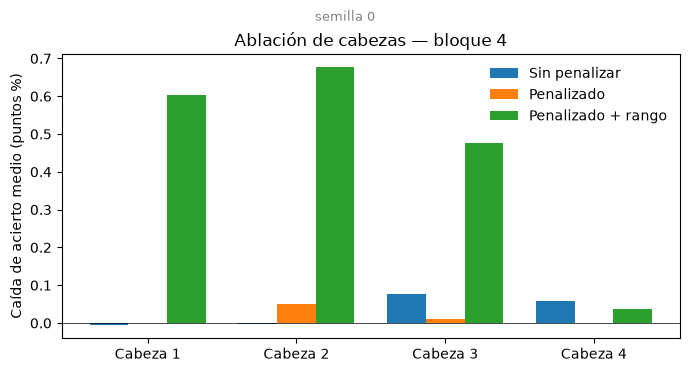

Sin penalizar        caída media 0.032 pts | Gini 0.53
Penalizado           caída media 0.015 pts | Gini 0.65
Penalizado + rango   caída media 0.448 pts | Gini 0.29


In [2]:
fig, ax = plt.subplots(figsize=(7, 3.6))
w = 0.26
for i, (k, name) in enumerate(VARIANTS.items()):
    ax.bar(np.arange(n_heads) + (i - 1) * w, npz[k]["drops"][BLOCK] * 100, w, label=name)
ax.set_xticks(range(n_heads)); ax.set_xticklabels([f"Cabeza {h+1}" for h in range(n_heads)])
ax.set_ylabel("Caída de acierto medio (puntos %)"); ax.axhline(0, color="k", lw=.5)
ax.set_title("Ablación de cabezas — bloque 4"); ax.legend(frameon=False)
plt.tight_layout(); save(fig, "ablation_drop_b4.png"); plt.show()
for k in VARIANTS: print(f"{VARIANTS[k]:20s} caída media {npz[k]['drops'][BLOCK].mean()*100:.3f} pts | Gini {res[k]['abl_b4_gini']:.2f}")

## 2. La huella de cada cabeza: daño por atributo

Cada fila es una cabeza, cada columna un atributo. Color más intenso = apagar esa cabeza hace perder más
acierto en ese atributo. **Si las filas se ven distintas entre sí, las cabezas se reparten el trabajo.**
Ojo: cada panel tiene su propia escala de color, mirar los números de la barra.

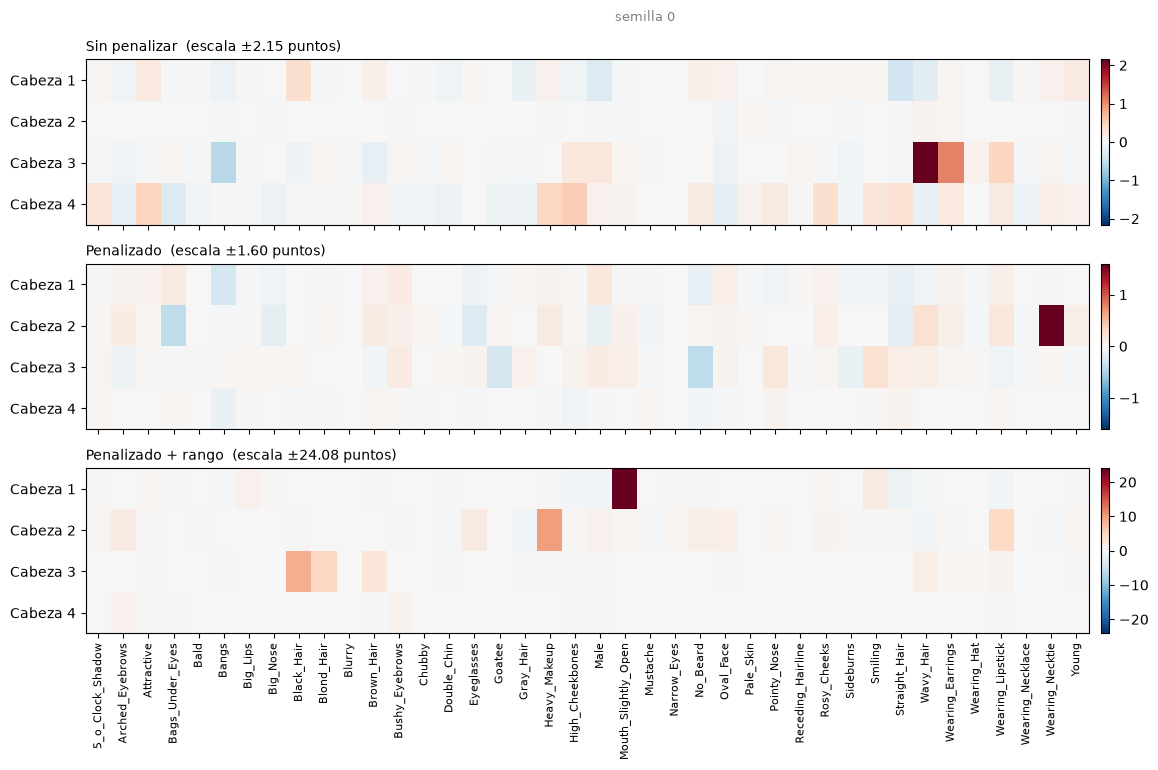

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(13, 7.5), sharex=True)
for ax, (k, name) in zip(axes, VARIANTS.items()):
    d = npz[k]["dmg"] * 100
    v = max(np.abs(d).max(), 1e-6)
    im = ax.imshow(d, aspect="auto", cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_yticks(range(n_heads)); ax.set_yticklabels([f"Cabeza {h+1}" for h in range(n_heads)])
    ax.set_title(f"{name}  (escala ±{v:.2f} puntos)", loc="left", fontsize=10)
    plt.colorbar(im, ax=ax, pad=0.01)
axes[-1].set_xticks(range(len(attrs))); axes[-1].set_xticklabels(attrs, rotation=90, fontsize=8)
plt.tight_layout(); save(fig, "damage_vectors.png"); plt.show()

## 3. ¿Se parecen las huellas entre cabezas? (coseno)

1 = apagar una u otra rompe exactamente lo mismo. 0 = rompen cosas sin relación.

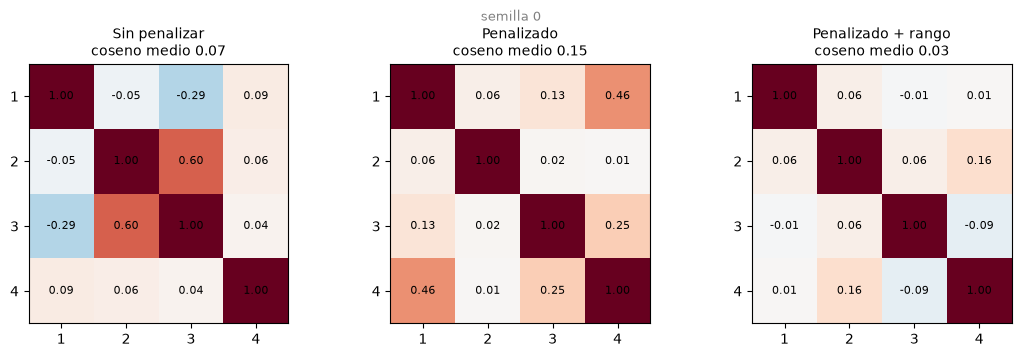

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (k, name) in zip(axes, VARIANTS.items()):
    d = np.nan_to_num(npz[k]["dmg"]); n = d / np.maximum(np.linalg.norm(d, axis=1, keepdims=True), 1e-12)
    im = ax.imshow(n @ n.T, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(n_heads)); ax.set_yticks(range(n_heads))
    ax.set_xticklabels(range(1, n_heads+1)); ax.set_yticklabels(range(1, n_heads+1))
    for i in range(n_heads):
        for j in range(n_heads): ax.text(j, i, f"{(n @ n.T)[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"{name}\ncoseno medio {res[k]['dmg_cosine_mean']:.2f}", fontsize=10)
plt.tight_layout(); save(fig, "damage_cosine.png"); plt.show()

## 4. El índice de especialización, desarmado en `same` y `cross`

Misma lógica de `evaluate_checkpoints_celeba.py`, recalculada acá para poder mostrar las dos partes.

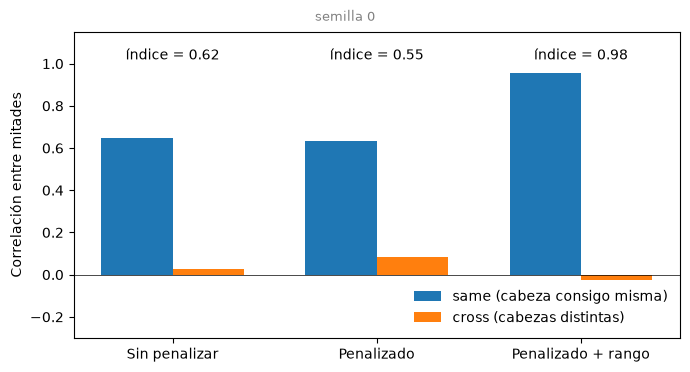

Sin penalizar        same 0.646 cross 0.025 índice 0.621 (guardado: 0.621)
Penalizado           same 0.632 cross 0.085 índice 0.547 (guardado: 0.558)
Penalizado + rango   same 0.956 cross -0.024 índice 0.979 (guardado: 0.979)
guardado en /Users/valefeve/Projects/interpretability of neural networks/interpretable-transformers/notebooks/01112026_head_specialization_celeba/results/seed0


In [5]:
def damage(preds, idx):
    tgt = Y[idx]
    acc = lambda p: (p[idx].astype(bool) == tgt).mean(0)
    base = acc(preds[0])
    return np.stack([base - acc(preds[1 + BLOCK * n_heads + h]) for h in range(n_heads)])

N = len(Y); rng = np.random.default_rng(0); out = {}
for k in VARIANTS:
    P = npz[k]["abl_preds"]; same, cross = [], []
    for _ in range(N_SPLITS):
        perm = rng.permutation(N); A, B = perm[: N // 2], perm[N // 2:]
        C_ = np.corrcoef(np.vstack([np.nan_to_num(damage(P, A)), np.nan_to_num(damage(P, B))]))[:n_heads, n_heads:]
        same.append(np.diag(C_).mean()); cross.append(C_[~np.eye(n_heads, dtype=bool)].mean())
    out[k] = (np.mean(same), np.mean(cross))

fig, ax = plt.subplots(figsize=(7, 3.6)); w = 0.35
ax.bar(np.arange(3) - w/2, [out[k][0] for k in VARIANTS], w, label="same (cabeza consigo misma)")
ax.bar(np.arange(3) + w/2, [out[k][1] for k in VARIANTS], w, label="cross (cabezas distintas)")
for i, k in enumerate(VARIANTS):
    ax.text(i, 1.02, f"índice = {out[k][0]-out[k][1]:.2f}", ha="center", fontsize=10)
ax.set_xticks(range(3)); ax.set_xticklabels(VARIANTS.values()); ax.set_ylim(-0.3, 1.15)
ax.axhline(0, color="k", lw=.5); ax.set_ylabel("Correlación entre mitades"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); save(fig, "specialization_index.png"); plt.show()
for k in VARIANTS: print(f"{VARIANTS[k]:20s} same {out[k][0]:.3f} cross {out[k][1]:.3f} índice {out[k][0]-out[k][1]:.3f} (guardado: {res[k]['dmg_specialization_index']:.3f})")

summary = {"seed": SEED, "block": BLOCK + 1, "variants": {k: {
    "accuracy": res[k]["accuracy"],
    "ablation_drop_b4_per_head_pts": (npz[k]["drops"][BLOCK] * 100).tolist(),
    "ablation_drop_b4_mean_pts": float(npz[k]["drops"][BLOCK].mean() * 100),
    "ablation_gini_b4": res[k]["abl_b4_gini"],
    "damage_cosine_mean": res[k]["dmg_cosine_mean"],
    "split_same": float(out[k][0]), "split_cross": float(out[k][1]), "specialization_index": float(out[k][0] - out[k][1]),
} for k in VARIANTS}}
(RESULTS / "summary.json").write_text(json.dumps(summary, indent=1))
print("guardado en", RESULTS)

## 5. Cómo leerlo

- **`cross` ≈ 0** significa que apagar una cabeza u otra no rompe los mismos atributos (las huellas son distintas).
- **`same` alto** significa que la huella de una cabeza es repetible entre mitades del test. Si apagar una cabeza casi
  no cambia nada (figura 1), `same` baja porque la huella es en buena parte ruido de medición, no porque las cabezas
  sean redundantes. Por eso el índice solo se interpreta junto con la figura 1.
- **Este notebook es una sola corrida de entrenamiento.** Las diferencias entre modelos que aparezcan aquí pueden ser
  de esa semilla. Con la semilla 0, por ejemplo, el índice de `constrained_rank` fue 0.98, pero en las semillas 1 y 2
  no se repitió. Para conclusiones, comparar los `summary.json` de `results/seed*/`.
